
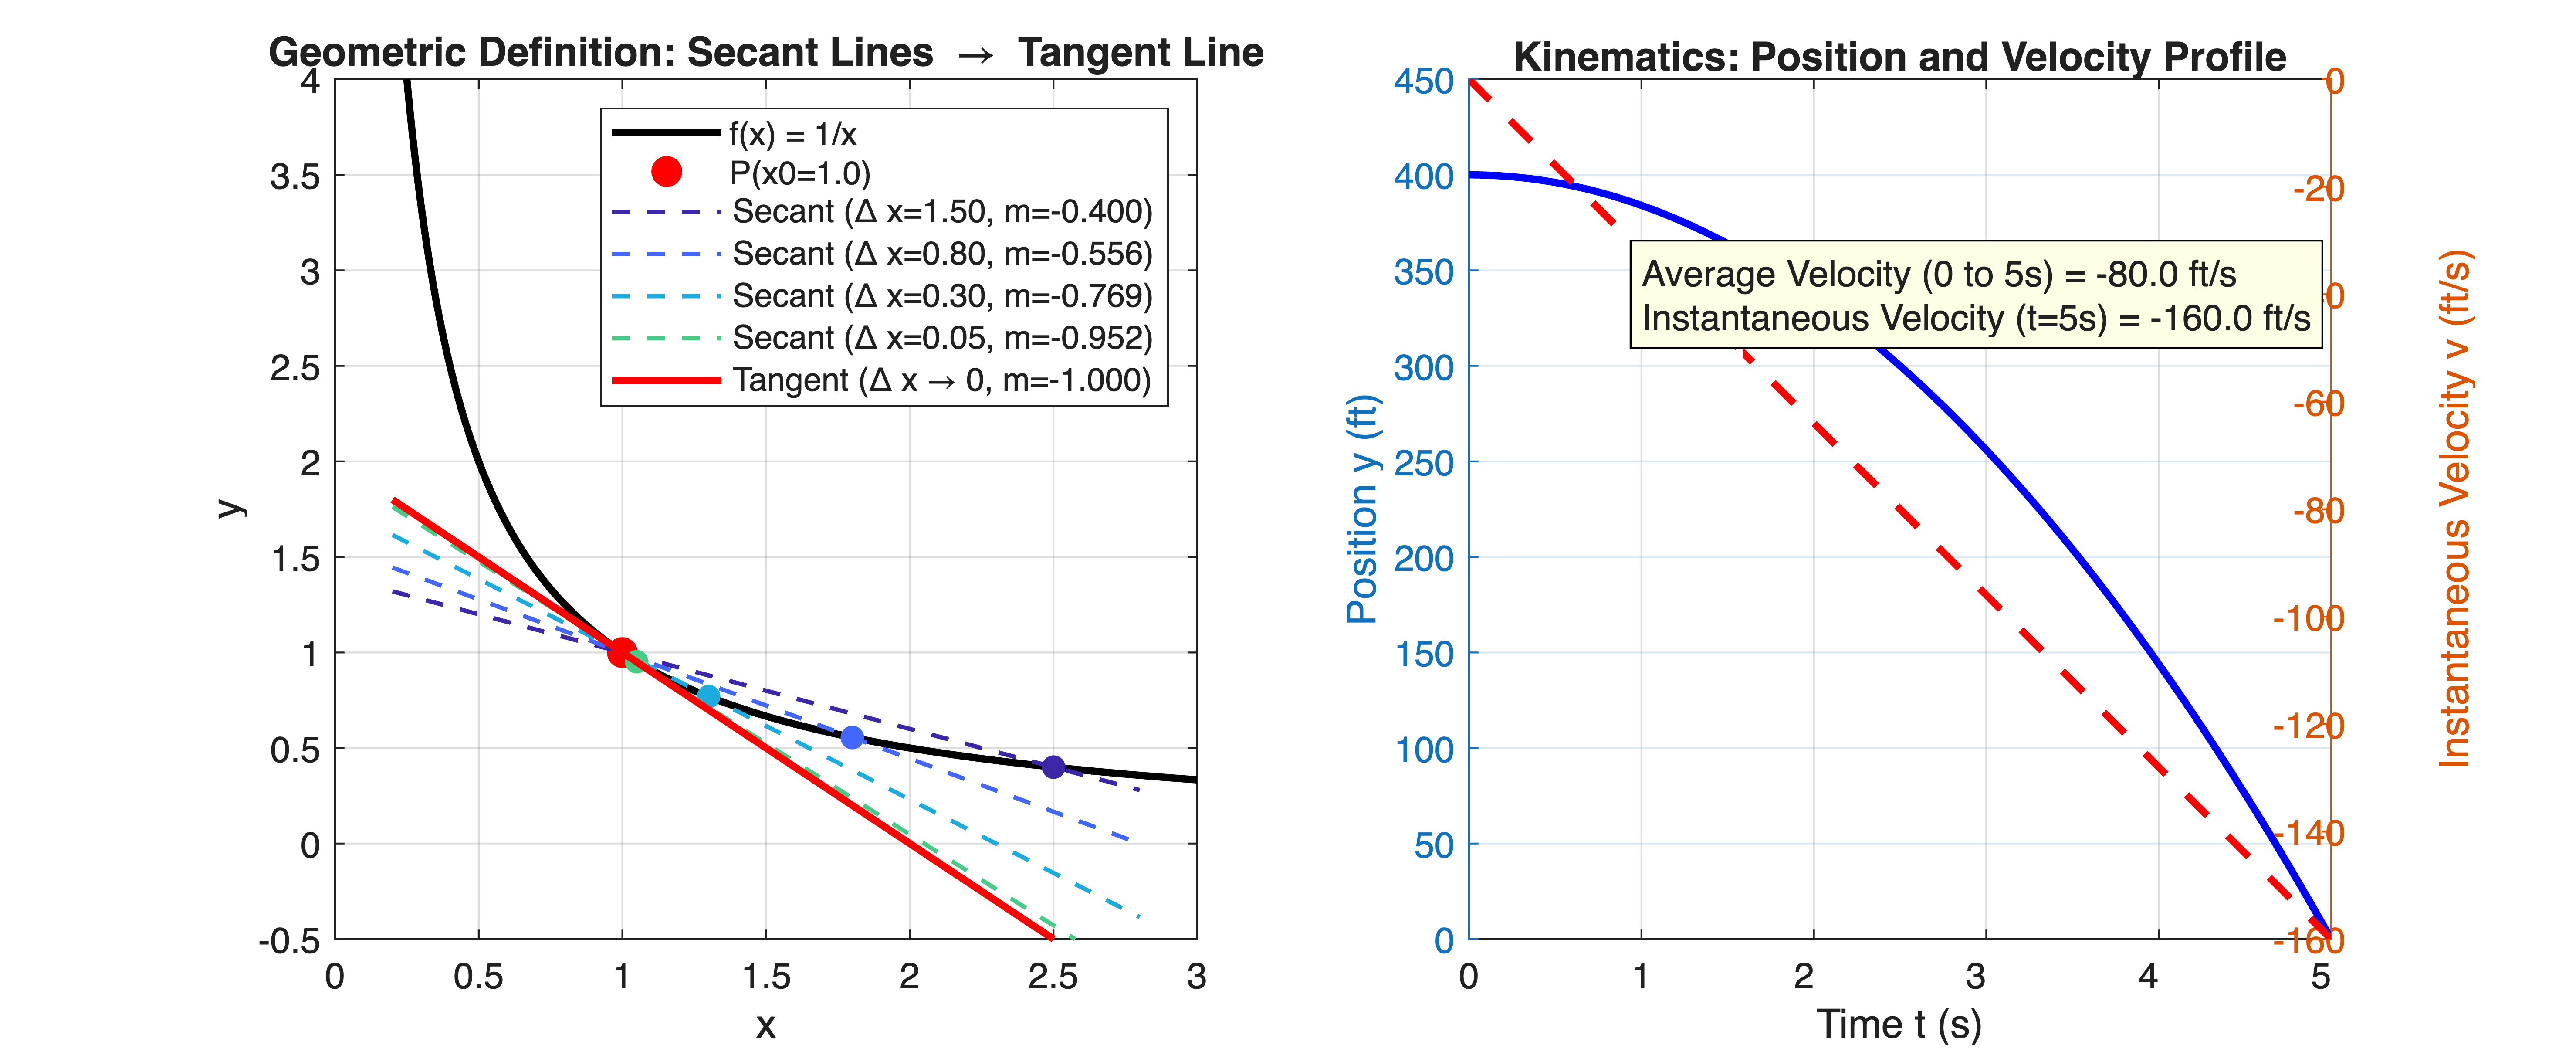

In [1]:
%% MIT 18.01 Lecture 1: Secant Line Limit and Kinematics Simulation
% Mathematical Tool Application: Used for local linearization and
% numerical finite-difference approximation of derivatives in dynamic systems.


clear; clc; close all;


%% Part 1: Geometric Limit of Secant Lines (f(x) = 1/x)
% Base function and operating point
f = @(x) 1 ./ x;
df_analytic = @(x) -1 ./ (x.^2);
x0 = 1.0;
y0 = f(x0);


% Domain grid for continuous curve
x_grid = linspace(0.2, 3.0, 400);
y_grid = f(x_grid);


% Increments of Delta x to illustrate convergence
delta_x_vals = [1.5, 0.8, 0.3, 0.05];


figure('Color', 'w', 'Position', [100, 100, 1100, 450]);


subplot(1, 2, 1);
plot(x_grid, y_grid, 'k-', 'LineWidth', 2, 'DisplayName', 'f(x) = 1/x'); hold on;
plot(x0, y0, 'ro', 'MarkerSize', 8, 'MarkerFaceColor', 'r', 'DisplayName', sprintf('P(x0=%.1f)', x0));


colors = parula(length(delta_x_vals) + 2);
for k = 1:length(delta_x_vals)
    dx = delta_x_vals(k);
    xq = x0 + dx;
    yq = f(xq);


    % Difference quotient calculation (secant slope)
    m_secant = (yq - y0) / dx;


    % Plot secant line across a local span
    x_sec = linspace(0.2, 2.8, 100);
    y_sec = y0 + m_secant * (x_sec - x0);
    plot(x_sec, y_sec, '--', 'Color', colors(k, :), 'LineWidth', 1.2, ...
        'DisplayName', sprintf('Secant (\\Delta x=%.2f, m=%.3f)', dx, m_secant));
    plot(xq, yq, 'o', 'Color', colors(k, :), 'MarkerFaceColor', colors(k, :), 'HandleVisibility', 'off');
end


% True tangent line (Delta x -> 0)
m_tangent = df_analytic(x0);
x_tan = linspace(0.2, 2.5, 100);
y_tan = y0 + m_tangent * (x_tan - x0);
plot(x_tan, y_tan, 'r-', 'LineWidth', 2, ...
    'DisplayName', sprintf('Tangent (\\Delta x\\rightarrow0, m=%.3f)', m_tangent));


grid on;
xlim([0, 3]); ylim([-0.5, 4]);
xlabel('x'); ylabel('y');
title('Geometric Definition: Secant Lines \rightarrow Tangent Line');
legend('Location', 'northeast');


%% Part 2: Physical Motion Dynamics (Free Fall: y = 400 - 16*t^2)
subplot(1, 2, 2);
t = linspace(0, 5, 200);
y_pos = 400 - 16 * t.^2;
v_inst = -32 * t;


yyaxis left
plot(t, y_pos, 'b-', 'LineWidth', 2);
ylabel('Position y (ft)');
xlabel('Time t (s)');
ylim([0, 450]);


yyaxis right
plot(t, v_inst, 'r--', 'LineWidth', 2);
ylabel('Instantaneous Velocity v (ft/s)');
title('Kinematics: Position and Velocity Profile');
grid on;


% Add annotation for impact conditions at t = 5s
t_impact = 5;
v_avg_total = (0 - 400) / t_impact;
v_inst_impact = -32 * t_impact;


annotation_text = sprintf('Average Velocity (0 to 5s) = %.1f ft/s\nInstantaneous Velocity (t=5s) = %.1f ft/s', ...
    v_avg_total, v_inst_impact);
text(1.0, -40, annotation_text, 'BackgroundColor', [1 1 0.9], 'EdgeColor', 'k');